### EX7: Simple Linear Regression on COVID-19 Datasets


### Learning simple linear regression

Task 0: First, run the example and understand the ML process and be familir with Python package functions for simple linear regression. 

Task 1: Apply a simple linear regression and a logistic regression on COVID-19 dataset(s). 

Task 2: A summary of your findings from simple regression modeling. 

#### Write full names of your team members who worked together.




#### Submission:

- Push the completed code to your Github repository.

- See submission details in Canvas. 

###  Simple Linear Regression example

Follow the code and observe the results

In [1]:
# Python ≥3.5 is required
import sys
assert sys.version_info >= (3, 5)

In [2]:
# Scikit-Learn ≥0.20 is required
import sklearn
assert sklearn.__version__ >= "0.20"

### Data Preparation

The code expects the data files to be located in the current directory. Fetch the files in datasets/lifesat.

In [3]:
import os
datapath = os.path.join("datasets", "lifesat", "")

In [4]:
# To plot pretty figures directly within Jupyter
%matplotlib inline
import matplotlib as mpl

mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)

In [5]:
import urllib.request

# Download the data
DOWNLOAD_ROOT = "https://raw.githubusercontent.com/ageron/handson-ml2/master/"

os.makedirs(datapath, exist_ok=True)

for filename in ("oecd_bli_2015.csv", "gdp_per_capita.csv"):
    print("Downloading", filename)
    url = DOWNLOAD_ROOT + "datasets/lifesat/" + filename
    urllib.request.urlretrieve(url, os.path.join(datapath, filename))


This function just merges the OECD's life satisfaction data and the IMF's GDP per capita data. It's a bit too long and boring and it's not specific to Machine Learning, which is why I left it out of the book.

#### Load the data into a DataFrame

In [6]:
# Code example of load the data and prepared the data
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn.linear_model

# Load the data
oecd_bli = pd.read_csv(datapath + "oecd_bli_2015.csv", thousands=',')
gdp_per_capita = pd.read_csv(datapath + "gdp_per_capita.csv",thousands=',',delimiter='\t',
                             encoding='latin1', na_values="n/a")

#### A function to select the data and visualize it

In [7]:
def prepare_country_stats(oecd_bli, gdp_per_capita):
    oecd_bli = oecd_bli[oecd_bli["INEQUALITY"]=="TOT"]
    oecd_bli = oecd_bli.pivot(index="Country", columns="Indicator", values="Value")
    gdp_per_capita.rename(columns={"2015": "GDP per capita"}, inplace=True)
    gdp_per_capita.set_index("Country", inplace=True)
    
    full_country_stats = pd.merge(left=oecd_bli, right=gdp_per_capita,
                                  left_index=True, right_index=True)
    
    full_country_stats.sort_values(by="GDP per capita", inplace=True)
    remove_indices = [0, 1, 6, 8, 33, 34, 35]
    keep_indices = list(set(range(36)) - set(remove_indices))
    
    return full_country_stats[['GDP per capita', 'Life satisfaction']].iloc[keep_indices]

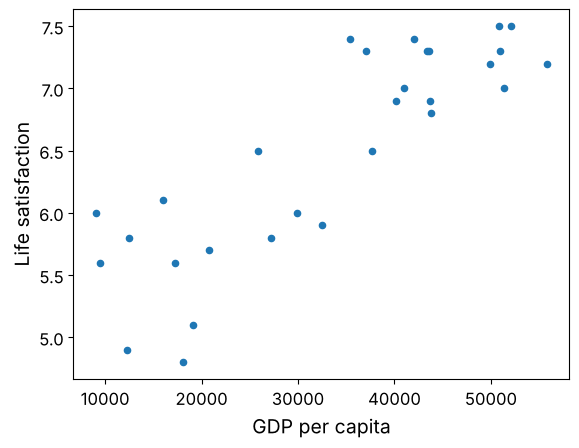

In [8]:
# Prepare the data
country_stats = prepare_country_stats(oecd_bli, gdp_per_capita)

X = np.c_[country_stats['GDP per capita']]
y = np.c_[country_stats['Life satisfaction']]

# Visualize the data
country_stats.plot(kind='scatter', x="GDP per capita", y='Life satisfaction')
plt.show()

In [9]:
# check sahpes of X and y
print(X.shape, y.shape)

(29, 1) (29, 1)


In [10]:
# check data values
print(X[:5])
print(y[:5])

[[ 9054.914]
 [ 9437.372]
 [12239.894]
 [12495.334]
 [15991.736]]
[[6. ]
 [5.6]
 [4.9]
 [5.8]
 [6.1]]


### Build a simple regression model


#### Create a simple linear regression 

https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

In [11]:
# import model
from sklearn.linear_model import LinearRegression


# Create a simple linear regression model
model = LinearRegression()

# Train the model
# This time we use all data for training
# Later (always in our analysis) we will divide the data into training data and testing data
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[0.]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[4.85]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[77520.92]


In [12]:
# check the properties of the model
# coefficient and intercept

print(model.coef_)
print(model.intercept_)

[[4.91154459e-05]]
[4.8530528]


#### Predict y for a new X value

In [13]:
# Make a prediction for Cyprus 
# new data value 22587 for Cyprus's GDP per capita

X_new = [[22587]]

y_predict = model.predict(X_new)

y_predict

array([[5.96242338]])

#### Plot a scatter graph together with the regression function

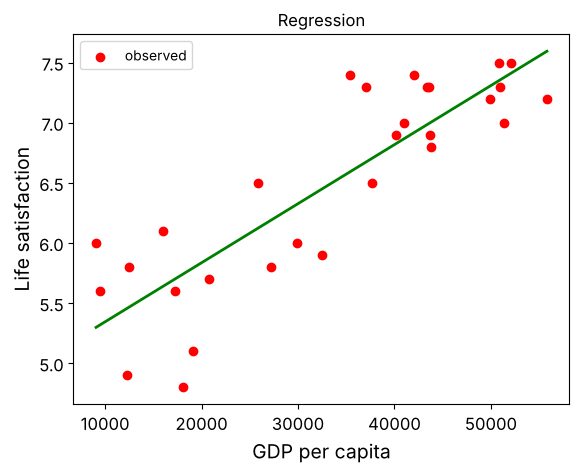

In [14]:
# Plot scatterplot 
plt.scatter(X, y, c='red', label='observed')
plt.legend(loc='best')

plt.xlabel('GDP per capita')
plt.ylabel('Life satisfaction')
plt.title('Regression')

# plot the regression together with the data
plt.plot(X,model.predict(X),c='g',label='fitted',linewidth=2)

plt.show()

## Model evaluation metrics for regression

Evaluation metrics for classification problems, such as **accuracy**, are not useful for regression problems. Instead, we need evaluation metrics designed for comparing continuous values.

Let's create some example numeric predictions, and calculate **three common evaluation metrics** for regression problems:

See more details: https://scikit-learn.org/stable/modules/model_evaluation.html


**Mean Absolute Error** (MAE) is the mean of the absolute value of the errors:

$$\frac 1n\sum_{i=1}^n|y_i-\hat{y}_i|$$

**Mean Squared Error** (MSE) is the mean of the squared errors:

$$\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2$$


**Root Mean Squared Error** (RMSE) is the square root of the mean of the squared errors:

$$\sqrt{\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2}$$


Comparing these metrics:

- **MAE** is the easiest to understand, because it's the average error.
- **MSE** is more popular than MAE, because MSE "punishes" larger errors.
- **RMSE** is even more popular than MSE, because RMSE is interpretable in the "y" units.


### The R2 ("r-squared") Regression Score

- Measures how well a prediction model for regression fits the given data.

- The score is between 0 and 1:

     - A value of 0 corresponds to a constant model that predicts the mean value of all training target values.

     - A value of 1 corresponds to perfect prediction

- Also known as "coefficient of determination"


### Model Evaluation Example

#### 1. Preparing X and y using pandas
- We already did this process above
- scikit-learn expects X (feature matrix) and y (response vector) to be NumPy arrays.
- However, pandas is built on top of NumPy.
- Thus, X can be a pandas DataFrame and y can be a pandas Series!

See more details about Pandas Series and Numpy

- https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.html

#### 2. Splitting X and y into training and testing sets

We are using the same data that is stored X, y above. 

In [15]:
from sklearn.model_selection import train_test_split

# split the data into training and testing (test data size 30%)

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3, random_state=1)

#### 3. Linear regression in scikit-learn

In [16]:
# import model
from sklearn.linear_model import LinearRegression


# instantiate a simple linear regression model 
linreg=LinearRegression()

# fit the model to the training data (learn the coefficients)

linreg.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[0.]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[4.84]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[66589.19]


#### 4. Making predictions for testing data

Use X_test

In [17]:
# make predictions on the testing set
y_pred=linreg.predict(X_test)

y_pred

array([[6.59031623],
       [6.90629497],
       [6.82350342],
       [6.90057464],
       [7.24870458],
       [6.88774681],
       [5.42891846],
       [6.12434396],
       [7.19687366]])

#### 5. Computing the RMSE 

https://scikit-learn.org/stable/modules/model_evaluation.html

In [18]:
from sklearn import metrics

rmse = np.sqrt(metrics.mean_squared_error(y_test,y_pred))
rmse

np.float64(0.39596209321120784)

#### 6. K Cross Validation and Learning Curve

In [19]:
import statistics as st
from sklearn.model_selection import KFold # import k-fold validation

kf = KFold(n_splits=3, random_state=None, shuffle=True) # Define the split - into 3 folds 

kf.get_n_splits(X) # returns the number of splitting iterations in the cross-validator

print(kf) 

KFold(n_splits=3, random_state=None, shuffle=True)

##### Setting up a testbed using KFold 

In [20]:
# Let's create a new simple linear regressor
linreg=LinearRegression()

# Conduct 3-fold cross validation
rmse=[]
r2 =[]

for train_index, test_index in kf.split(X):
    X_train, X_test = X[train_index],X[test_index]
    y_train, y_test = y[train_index],y[test_index]
    
    linreg.fit(X_train, y_train)
    y_pred = linreg.predict(X_test)
    
    rmse.append(np.sqrt(metrics.mean_squared_error(y_test,y_pred)))
    r2.append(metrics.r2_score(y_test,y_pred))
    

print(rmse)
print(r2)

[np.float64(0.4799983090103211), np.float64(0.36935942797883137), np.float64(0.5587385284788786)]
[0.42457947888919145, 0.7927910281943356, 0.6497605512500534]


#### Learning Curve

Check the details for learning curve

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.learning_curve.html

In [21]:
from sklearn.model_selection import learning_curve
    
# evaluate the training and testing and
# retrieve the information of model performance. 
train_sizes = np.linspace(0.2,0.8,5)  # 5 times 5*3 = 15

train_sizes, train_mse, test_mse = learning_curve(linreg, X, y, 
                            train_sizes = train_sizes, 
                            scoring = 'neg_mean_squared_error',
                                                 cv=3, shuffle=True)
train_scores = np.sqrt(np.abs(train_mse))

test_scores = np.sqrt(np.abs(test_mse))

print(train_scores)
print(test_scores) 

train_scores_mean=np.mean(train_scores, axis=1)

test_scores_mean = np.mean(test_scores, axis=1)

[[0.01445183 0.23238327 0.09677329]
 [0.30473713 0.37080413 0.40424948]
 [0.29080555 0.34560429 0.42233744]
 [0.28694704 0.34450505 0.49749136]
 [0.36392327 0.36909513 0.49285562]]
[[0.66532542 0.45686797 0.44934261]
 [0.52389845 0.45570276 0.21908612]
 [0.59993686 0.44711882 0.41221059]
 [0.680646   0.44467028 0.46526123]
 [0.53410783 0.46808739 0.50285131]]


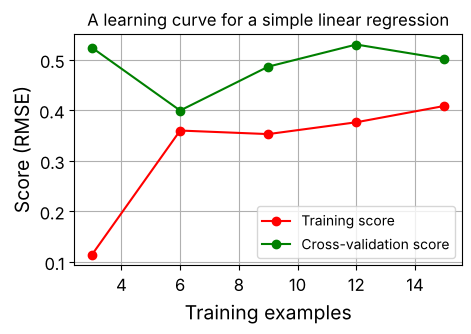

In [22]:
# Plot learning curve
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
    
ax.set_title('A learning curve for a simple linear regression')
ax.set_xlabel("Training examples")
ax.set_ylabel("Score (RMSE)")
ax.grid()

ax.plot(train_sizes, train_scores_mean, 'o-', color="r", label="Training score")
ax.plot(train_sizes, test_scores_mean, 'o-', color="g", label="Cross-validation score")
ax.legend(loc="best")

plt.show()

### Teamwork


###  Part 1: Regression Modeling

The following Git repository is for the COVID-19 visual dashboard operated by the Johns Hopkins University Center for Systems Science and Engineering:
https://github.com/CSSEGISandData/COVID-19

Read the information on the dashboard and check the datasets details

Datasets are located in a folder: csse_covid_19_data

### Tasks

1. Check your work in EX4 (EDA on COVID-19 datasets). In EX4, you conducted an EDA on your selected COVID-19 datasets through descriptive statistics and data visualization. The EDA analysis results may give you  insight of the selected data and relationships among the data attributes. 

2. Now, build a simple regression and plot the regression function with a scatter plot (as shown in the example above). 
    --> You may see the data does not follow a simple linear function. 
   
3. Build a logistic regression and draw a scatter plot of the data together with the logistic regression function. See the web resources below:

https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
 

#### Part 1 – Step 1: Load the JHU CSSE COVID-19 data and choose the variables

Dataset: `time_series_covid19_confirmed_global.csv` (JHU CSSE, `csse_covid_19_data/csse_covid_19_time_series`). I aggregate all US rows into one cumulative series. Feature **X** = day number since 2020-01-22; target **y** = cumulative confirmed cases.

(1143, 3)
        date  day  cases
0 2020-01-22    0      1
1 2020-01-23    1      1
2 2020-01-24    2      2
3 2020-01-25    3      2
4 2020-01-26    4      5
           date   day      cases
1138 2023-03-05  1138  103646975
1139 2023-03-06  1139  103655539
1140 2023-03-07  1140  103690910
1141 2023-03-08  1141  103755771
1142 2023-03-09  1142  103802702


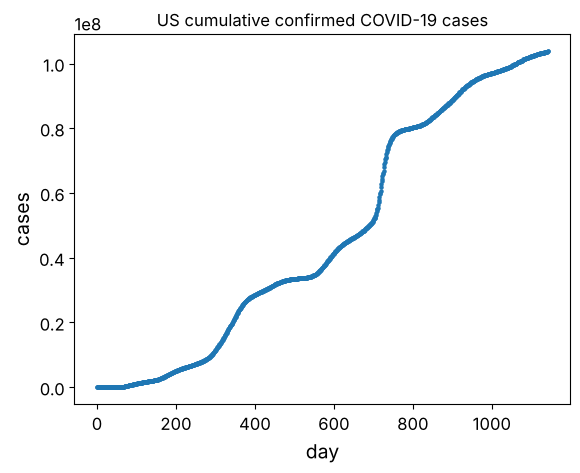

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
covid_path = os.path.join("datasets", "covid19", "time_series_covid19_confirmed_global.csv")
if not os.path.exists(covid_path):
    os.makedirs(os.path.dirname(covid_path), exist_ok=True)
    url = ("https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/"
           "csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv")
    urllib.request.urlretrieve(url, covid_path)

covid = pd.read_csv(covid_path)
us = covid[covid["Country/Region"] == "US"].iloc[:, 4:].sum()
us.index = pd.to_datetime(us.index, format="%m/%d/%y")

us_df = pd.DataFrame({"date": us.index, "day": np.arange(len(us)), "cases": us.values})
print(us_df.shape)
print(us_df.head())
print(us_df.tail())

us_df.plot(x="day", y="cases", kind="scatter", s=5)
plt.title("US cumulative confirmed COVID-19 cases")
plt.show()

#### Step 2: Simple linear regression (cases ~ day)

slope (new cases per day): 108720.50133281181
intercept: -14998754.98719477
R2 (all data): 0.968112253511955
Test R2: 0.9660552982803255
Test RMSE: 6786997.688114681


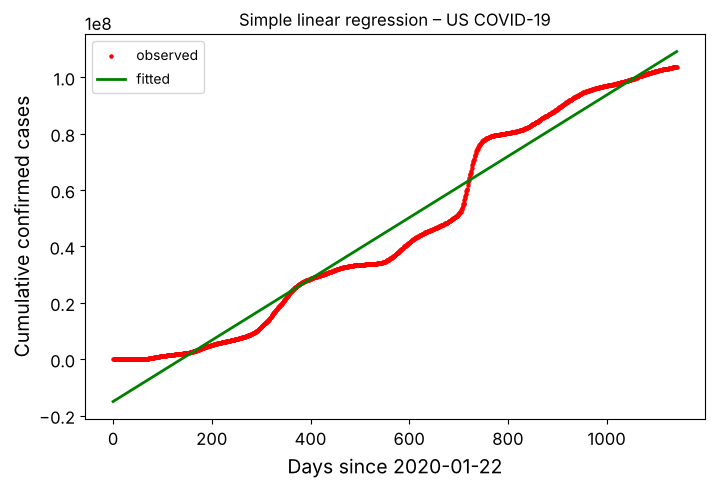

In [24]:
X_c = us_df[["day"]].values
y_c = us_df["cases"].values

# Fit on all data (as in the example) to see the shape of the fit
lin_c = LinearRegression().fit(X_c, y_c)
print("slope (new cases per day):", lin_c.coef_[0])
print("intercept:", lin_c.intercept_)
print("R2 (all data):", lin_c.score(X_c, y_c))

# Proper evaluation on a held-out test set (30%)
Xtr, Xte, ytr, yte = train_test_split(X_c, y_c, test_size=0.3, random_state=1)
lin_tt = LinearRegression().fit(Xtr, ytr)
print("Test R2:", lin_tt.score(Xte, yte))
print("Test RMSE:", np.sqrt(metrics.mean_squared_error(yte, lin_tt.predict(Xte))))

plt.figure(figsize=(8, 5))
plt.scatter(X_c, y_c, c="red", s=5, label="observed")
plt.plot(X_c, lin_c.predict(X_c), c="g", linewidth=2, label="fitted")
plt.xlabel("Days since 2020-01-22"); plt.ylabel("Cumulative confirmed cases")
plt.title("Simple linear regression – US COVID-19"); plt.legend(); plt.show()

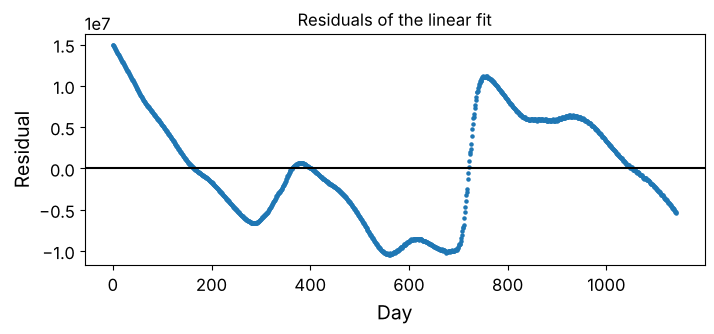

first   50 days: R2 = 0.333
first  200 days: R2 = 0.894
first 1143 days: R2 = 0.968


In [25]:
# Residuals show the model is systematically wrong (not random noise)
resid = y_c - lin_c.predict(X_c)
plt.figure(figsize=(8, 3))
plt.scatter(X_c, resid, s=5)
plt.axhline(0, c="k")
plt.xlabel("Day"); plt.ylabel("Residual"); plt.title("Residuals of the linear fit")
plt.show()

# R2 depends heavily on the time window: early phase vs. later phase
for k in [50, 200, len(us_df)]:
    sub = us_df[us_df["day"] < k]
    m = LinearRegression().fit(sub[["day"]], sub["cases"])
    print(f"first {k:4d} days: R2 = {m.score(sub[['day']], sub['cases']):.3f}")

#### Step 3: Logistic regression

Logistic regression needs a binary target. I define **y = 1 if cumulative cases exceed the median cumulative count** (about 36.8 million, first crossed on 2021-08-16), otherwise 0, and model the probability of this event as a function of the day.

threshold: 36845900.0 | class counts: {0: 572, 1: 571}
coef: [1.19457149] intercept: [-682.69759452]
accuracy (all data): 1.0
day where P = 0.5: 571.4999881242971


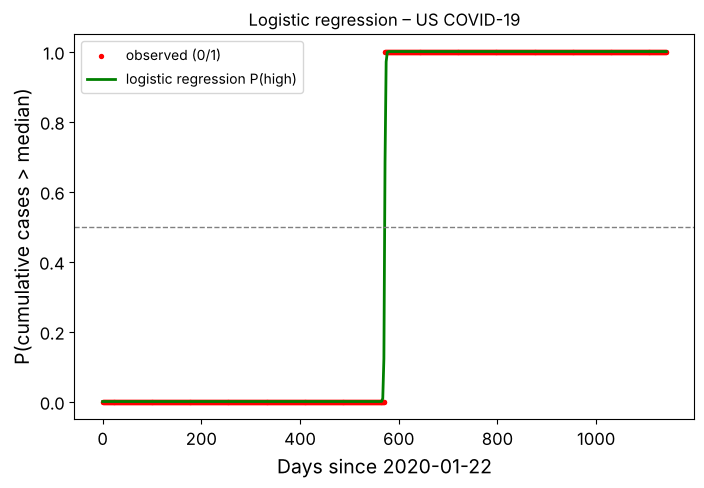

In [26]:
threshold = us_df["cases"].median()
us_df["high"] = (us_df["cases"] > threshold).astype(int)
print("threshold:", threshold, "| class counts:", us_df["high"].value_counts().to_dict())

y_b = us_df["high"].values
log_reg = LogisticRegression().fit(X_c, y_b)
print("coef:", log_reg.coef_[0], "intercept:", log_reg.intercept_)
print("accuracy (all data):", log_reg.score(X_c, y_b))
print("day where P = 0.5:", -log_reg.intercept_[0] / log_reg.coef_[0][0])

# Plot data with the fitted logistic (sigmoid) function
xs = np.linspace(X_c.min(), X_c.max(), 500).reshape(-1, 1)
plt.figure(figsize=(8, 5))
plt.scatter(X_c, y_b, c="red", s=8, label="observed (0/1)")
plt.plot(xs, log_reg.predict_proba(xs)[:, 1], c="g", linewidth=2, label="logistic regression P(high)")
plt.axhline(0.5, c="gray", ls="--", lw=1)
plt.xlabel("Days since 2020-01-22"); plt.ylabel("P(cumulative cases > median)")
plt.title("Logistic regression – US COVID-19"); plt.legend(); plt.show()

test accuracy: 0.9970845481049563
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       172
           1       1.00      0.99      1.00       171

    accuracy                           1.00       343
   macro avg       1.00      1.00      1.00       343
weighted avg       1.00      1.00      1.00       343



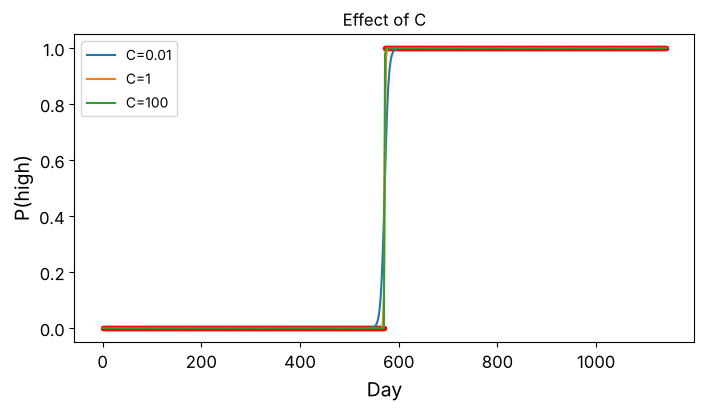

In [27]:
# Train/test check and effect of regularization strength C.
# The classes are perfectly separable by day (cases only increase), so a larger C
# makes the sigmoid approach a step function.
Xtr, Xte, ytr, yte = train_test_split(X_c, y_b, test_size=0.3, random_state=1, stratify=y_b)
lr_tt = LogisticRegression().fit(Xtr, ytr)
print("test accuracy:", lr_tt.score(Xte, yte))
print(classification_report(yte, lr_tt.predict(Xte)))

plt.figure(figsize=(8, 4))
plt.scatter(X_c, y_b, c="red", s=8)
for C_ in [0.01, 1, 100]:
    lr = LogisticRegression(C=C_, max_iter=5000).fit(X_c, y_b)
    plt.plot(xs, lr.predict_proba(xs)[:, 1], label=f"C={C_}")
plt.xlabel("Day"); plt.ylabel("P(high)"); plt.legend(); plt.title("Effect of C"); plt.show()

### Part 2: Write a summary of what you find from the data

**Data.** JHU CSSE global confirmed-cases time series, all US rows summed into one cumulative series: 1,143 days from 2020-01-22 to 2023-03-09 (about 1 case to about 103.8 million). Feature = day number, target = cumulative confirmed cases.

**Simple linear regression.**
- The fit gives a slope of about 108,700 cases per day and an intercept of about -15.0 million. R2 is 0.968 on all data and 0.966 on a 30% held-out test set, with a test RMSE of about 6.8 million cases.
- The high R2 is misleading. The residual plot shows a clear systematic pattern (positive at both ends, negative in the middle), so the straight line is the wrong shape for this data. The curve is closer to an S-shape: slow start, rapid growth during the waves, then flattening as testing and reporting declined.
- The intercept is negative, which is impossible for a case count, and a 6.8 million RMSE is large relative to the early-period values.
- R2 depends on the time window: 0.33 for the first 50 days, 0.89 for the first 200 days, 0.97 for the whole series. A linear model can look good over a long range simply because the range is large.
- Because the series is cumulative and the days are ordered, neighboring points are strongly autocorrelated. A random train/test split therefore overstates generalization.

**Logistic regression.**
- I converted the target to a binary label: 1 if cumulative cases exceed the median (about 36.8 million, first crossed on 2021-08-16). Classes are balanced (572 vs 571).
- The fitted sigmoid crosses P = 0.5 at about day 571, matching the median crossing, with 100% accuracy on all data and 99.7% on a stratified test split.
- The perfect score is not a sign of a strong model. Cumulative counts only increase, so the label is a monotone function of the day and the classes are perfectly separable. The C comparison shows the sigmoid steepening toward a step function as regularization weakens.
- Logistic regression fits the shape of the data (an S-curve) better than a straight line, but the task here is trivial. It would be more informative with a non-monotone label, such as whether a day's new cases exceed some level, using more features.

**Takeaways and next steps.**
- Neither model is a good forecasting tool. Epidemic curves are driven by waves, variants, behavior, and reporting changes, none of which a single time variable captures.
- Better options: model daily new cases rather than cumulative, use log(cases) for the early exponential phase, add polynomial or logistic-growth curves, or use time-series methods.
- Per-capita comparisons across states or countries would also give the regression more informative features than time alone.
